<a href="https://colab.research.google.com/github/AntonySSk/Machine_Learning/blob/dev/%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%A8%D0%BA%D0%BE%D0%BB%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Школа Антон  
**Група:** 3-9  
**Дата:** 27.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [ ]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [ ]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

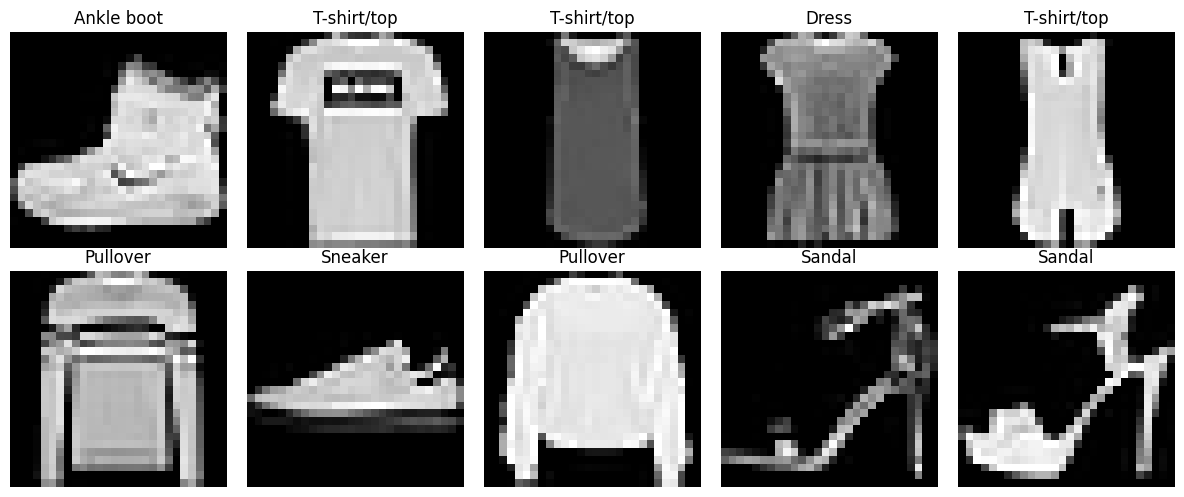

In [ ]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(10):
    ax = axes[i // 5, i % 5]
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [ ]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("x_train min/max:", x_train.min(), x_train.max(), "dtype:", x_train.dtype)
print("x_test min/max:", x_test.min(), x_test.max(), "dtype:", x_test.dtype)

x_train min/max: 0.0 0.003921569 dtype: float32
x_test min/max: 0.0 0.003921569 dtype: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

Кількість нейронів (256 і 128): 784 вхідні ознаки (28×28) стискаються поступово - цього достатньо для розпізнавання ознак одягу на Fashion MNIST і легко дає точність вище 0.87 без зайвої ваги моделі.

Dropout (0.3 і 0.2): вимикає частину нейронів під час навчання, щоб мережа не запам'ятовувала навчальні картинки і менше перенавчалася.

Швидкість навчання (1e-3 для Adam): стандартний старт для Adam - швидко збігається на початку, а далі зменшується через ReduceLROnPlateau.

In [ ]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5552 - loss: 1.2290 - val_accuracy: 0.7360 - val_loss: 0.7267 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7331 - loss: 0.7080 - val_accuracy: 0.7782 - val_loss: 0.5983 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7728 - loss: 0.6147 - val_accuracy: 0.8004 - val_loss: 0.5430 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7957 - loss: 0.5588 - val_accuracy: 0.8172 - val_loss: 0.5038 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8115 - loss: 0.5183 - val_accuracy: 0.8268 - val_loss: 0.4770 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8215 - loss: 0.4928 - val_accuracy: 0.8323 - val_loss: 0.4568 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8312 - loss: 0.4

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save("fashion_mnist_model.keras")

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

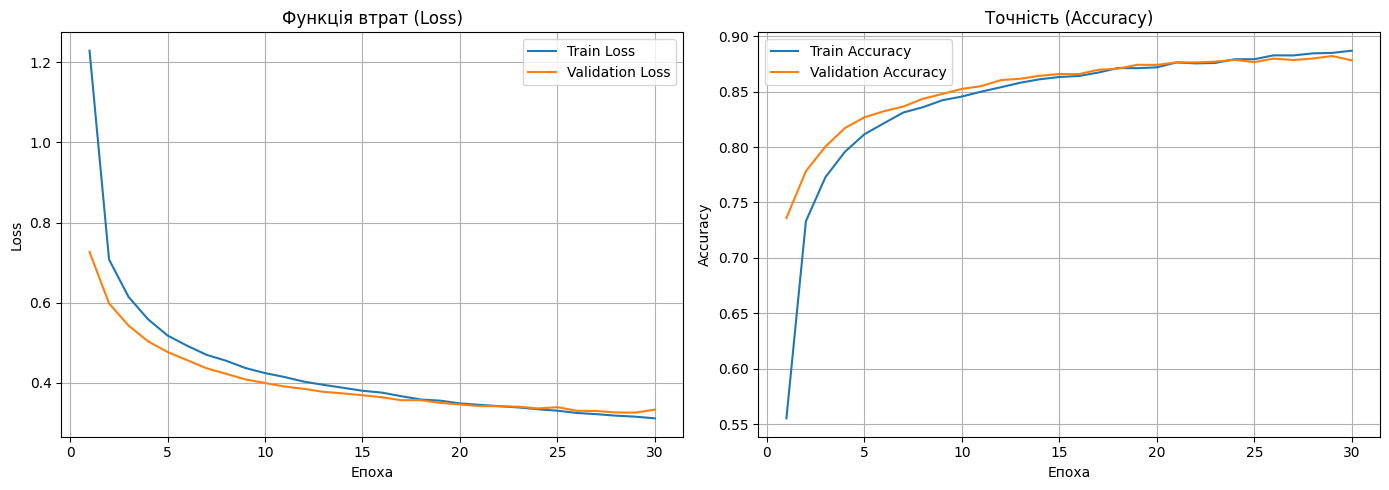

In [ ]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["loss"], label="Train Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.title("Функція втрат (Loss)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["accuracy"], label="Train Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Точність (Accuracy)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.87:
    print("Поріг точності 0.87 досягнуто.")
else:
    print("Поріг точності 0.87 не досягнуто.")

y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test loss: 0.3547
Test accuracy: 0.8740
Поріг точності 0.87 досягнуто.
              precision    recall  f1-score   support

 T-shirt/top     0.8113    0.8640    0.8368      1000
     Trouser     0.9817    0.9640    0.9728      1000
    Pullover     0.7498    0.8270    0.7865      1000
       Dress     0.8642    0.8970    0.8803      1000
        Coat     0.7644    0.8080    0.7856      1000
      Sandal     0.9520    0.9510    0.9515      1000
       Shirt     0.7567    0.5630    0.6456      1000
     Sneaker     0.9320    0.9450    0.9384      1000
         Bag     0.9682    0.9730    0.9706      1000
  Ankle boot     0.9547    0.9480    0.9513      1000

    accuracy                         0.8740     10000
   macro avg     0.8735    0.8740    0.8719     10000
weighted avg     0.8735    0.8740    0.8719     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

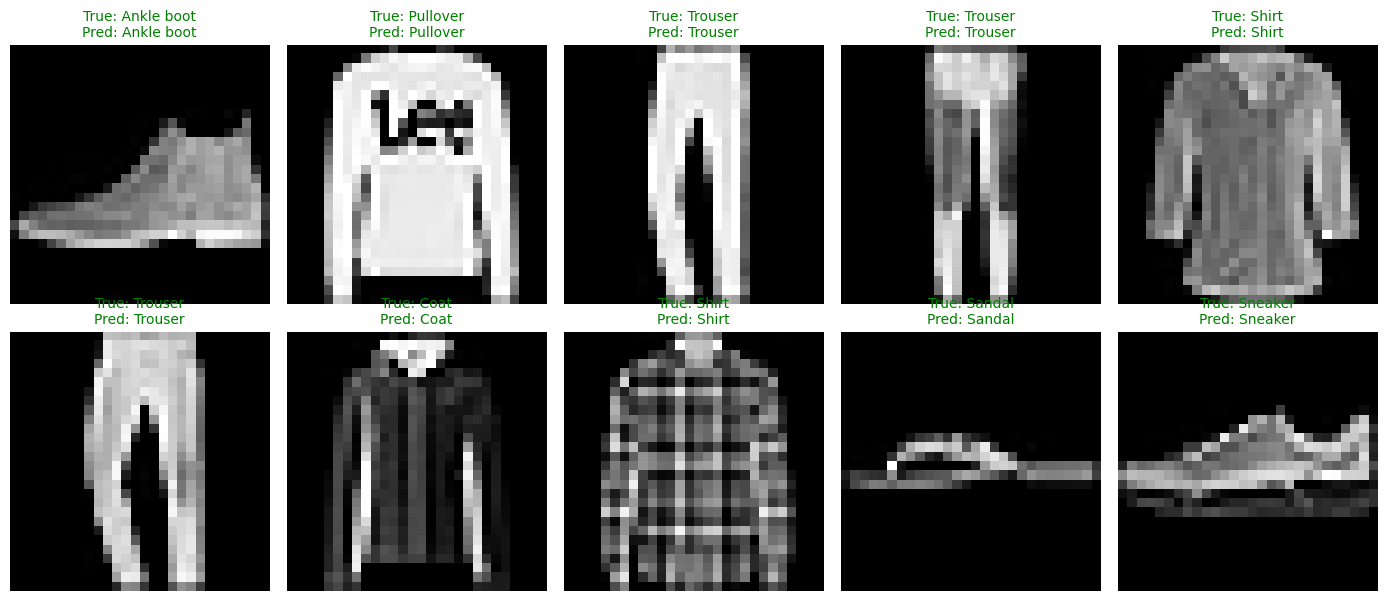

In [ ]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i in range(10):
    ax = axes[i // 5, i % 5]
    true_label = y_test[i]
    pred_label = y_pred[i]
    is_correct = true_label == pred_label
    color = "green" if is_correct else "red"

    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}",
        color=color,
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Модель досягла тестової точності 0.8740 (втрати на тесті — 0.3547), тому вимогу щодо мінімальної точності не нижче 0.87 виконано.

Найбільше помилок модель робить на класах верхнього одягу, які візуально схожі між собою: найгірший результат у Shirt (F1-score 0.6456, низький recall 0.5630), а також помітно складнішими є Coat (F1-score 0.7856) та Pullover (F1-score 0.7865). Найкраще розпізнаються Trouser (F1-score 0.9728), Bag (0.9706) і взуття (Sandal, Sneaker, Ankle boot - понад 0.93).

Архітектура з шарами 256 та 128 нейронів із ReLU, Dropout (0.3 і 0.2) і Adam (lr=1e-3) навчилася стабільно та без сильного перенавчання: графіки loss і accuracy для навчальної і валідаційної вибірок йдуть близько одна до одної.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner
import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_val = x_train_full[-10000:]
y_val = y_train_full[-10000:]

x_train_tune = x_train_full[:-10000]
y_train_tune = y_train_full[:-10000]

print("Train shape:", x_train_tune.shape, y_train_tune.shape)
print("Val shape:", x_val.shape, y_val.shape)
print("Test shape:", x_test.shape, y_test.shape)

Train shape: (50000, 28, 28) (50000,)
Val shape: (10000, 28, 28) (10000,)
Test shape: (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Flatten(input_shape=(28, 28)))

    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(
            layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=l2(1e-4),
            )
        )
        model.add(layers.Dropout(0.2))

    model.add(layers.Dense(10, activation="softmax"))

    learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="fashion_mnist_tuning",
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

reduce_lr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
)

tuner.search(
    x_train_tune,
    y_train_tune,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr_cb],
    verbose=1,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:", best_hp.values)

best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

best_history = best_model.fit(
    x_train_tune,
    y_train_tune,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr_cb],
    verbose=1,
)

Trial 3 Complete [00h 01m 23s]
val_accuracy: 0.8932999968528748

Best val_accuracy So Far: 0.8932999968528748
Total elapsed time: 00h 03m 24s
Найкращі гіперпараметри: {'num_layers': 3, 'units_0': 96, 'learning_rate': 0.001, 'units_1': 192, 'units_2': 192}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 96)             │        75,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 192)            │        18,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 192)            │        37,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,930 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,970 (519.41 KB)

 Trainable params: 132,970 (519.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7573 - loss: 0.7152 - val_accuracy: 0.8377 - val_loss: 0.4859 - learning_rate: 0.0010
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8403 - loss: 0.4937 - val_accuracy: 0.8594 - val_loss: 0.4388 - learning_rate: 0.0010
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8515 - loss: 0.4554 - val_accuracy: 0.8642 - val_loss: 0.4193 - learning_rate: 0.0010
Epoch 4/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8625 - loss: 0.4294 - val_accuracy: 0.8706 - val_loss: 0.4077 - learning_rate: 0.0010
Epoch 5/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8653 - loss: 0.4161 - val_accuracy: 0.8710 - val_loss: 0.4057 - learning_rate: 0.0010
Epoch 6/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8710 - loss: 0.4045 - val_accuracy: 0.8719 - val_loss: 0.4095 - learning_rate: 0.0010
Epoch 7/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8731 - loss: 0.3937

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Best model test loss: 0.3624
Best model test accuracy: 0.8901


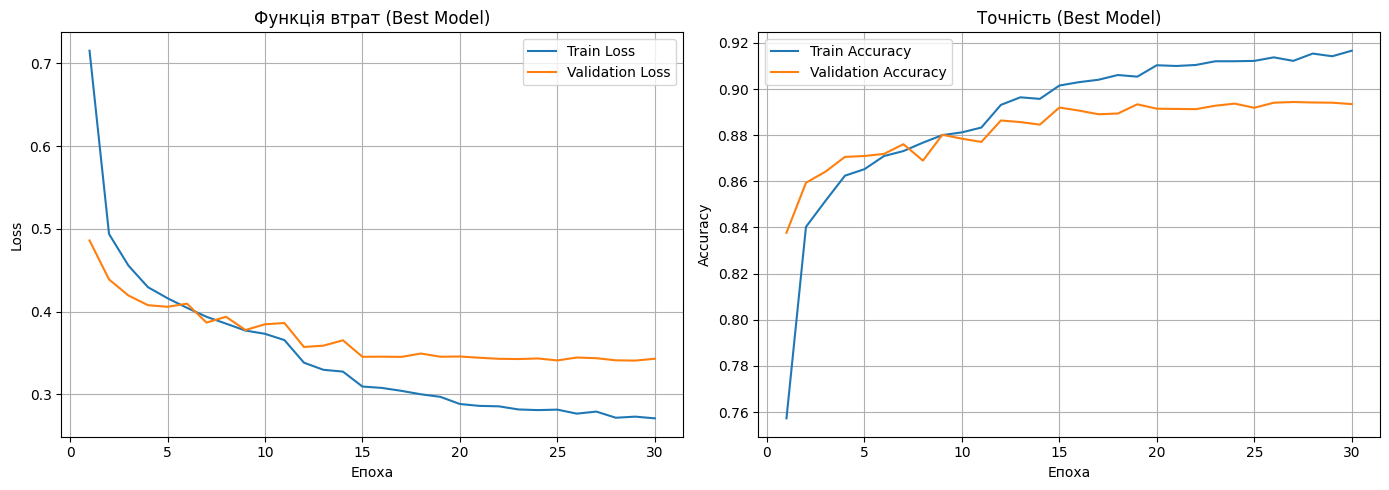

In [ ]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best model test loss: {best_test_loss:.4f}")
print(f"Best model test accuracy: {best_test_accuracy:.4f}")

epochs_best = range(1, len(best_history.history["loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_best, best_history.history["loss"], label="Train Loss")
plt.plot(epochs_best, best_history.history["val_loss"], label="Validation Loss")
plt.title("Функція втрат (Best Model)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_best, best_history.history["accuracy"], label="Train Accuracy")
plt.plot(epochs_best, best_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Точність (Best Model)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 3 |
| Кількість нейронів | 256, 128 | 96, 192, 192 |
| Швидкість навчання | 0.001 | 0.001 (зменшувалась до 6.25e-5) |
| Точність на тестовій вибірці (accuracy) | 0.8740 | 0.8901 |
| Втрати на тестовій вибірці (loss) | 0.3547 | 0.3624 |
| Кількість епох навчання | 30 | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
Поріг у 0.87 у завданні 1: так, досягнуто - тестова точність склала 0.8740.

Вплив підбору гіперпараметрів: так, точність на тесті зросла з 0.8740 до 0.8901 (+0.0161).

Найкращі гіперпараметри та різниця між запусками: найкращими вийшли 3 приховані шари, 96, 192 та 192 нейрони і швидкість навчання 0.001. Результат між запусками може відрізнятися через випадкову ініціалізацію ваг, перемішування даних, роботу Dropout, RandomSearch і зміну learning_rate.

Найскладніші класи: найважче розпізнавати схожий верхній одяг - Shirt, Coat та Pullover.

Модель після Keras Tuner показала вищу точність на тестових даних (0.8901 проти 0.8740), хоча тестовий loss трохи підріс (0.3624 проти 0.3547). Загалом обидві мережі навчилися стабільно, а автоматичний підбір допоміг знайти кращу конфігурацію без використання тестової вибірки під час пошуку.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.